# Retail Transactions — EDA Walkthrough

A guided notebook companion to `main.py`. Run cells from top to bottom.

In [ ]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data_loader import load_data
from src.data_cleaning import clean_data
from src.analysis import build_analysis
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 1. Load and inspect raw data

In [ ]:
raw = load_data(ROOT / 'data/raw/retail_transactions.csv')
print('Shape:', raw.shape)
display(raw.head())
raw.info()
display(raw.describe(include='all').T)

Shape: (2512, 13)


,order_id,order_date,customer_id,region,category,product,quantity,unit_price,discount,payment_method,sales,cost,profit
0,ORD000001,2024-03-06,C00776,North,Electronics,Wireless Headphones,1,9625.89,0.10,Debit Card,8663.30,5935.00,2728.30
1,ORD000002,2025-07-19,C00148,North,Clothing,Running Shoes,4,3769.02,0.15,Credit Card,12814.67,11591.58,1223.08
2,ORD000003,2025-04-23,C00646,North,Clothing,T-Shirt,2,1265.84,0.00,Net Banking,2531.68,1298.50,1233.18
3,ORD000004,2024-11-16,C00596,East,Books,Python Handbook,4,615.98,0.00,UPI,2759.59,1602.51,1157.08
4,ORD000005,2024-11-12,C00599,North,Clothing,Jeans,3,2849.64,0.10,UPI,8617.31,4978.77,3638.54


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        2512 non-null   object 
 1   order_date      2512 non-null   object 
 2   customer_id     2512 non-null   object 
 3   region          2497 non-null   object 
 4   category        2512 non-null   object 
 5   product         2512 non-null   object 
 6   quantity        2512 non-null   int64  
 7   unit_price      2512 non-null   float64
 8   discount        2501 non-null   float64
 9   payment_method  2502 non-null   object 
 10  sales           2512 non-null   float64
 11  cost            2512 non-null   float64
 12  profit          2512 non-null   float64
dtypes: float64(5), int64(1), object(7)
memory usage: 255.3+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,2512,2500,ORD000998,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,2512,700,2024-11-24,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,2512,800,C00646,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2497,5,North,600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2512,5,Clothing,639,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,2512,20,Jeans,192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,2512.0,NaN,NaN,NaN,3.062102,1.716033,1.0,2.0,3.0,4.0,25.0
unit_price,2512.0,NaN,NaN,NaN,4797.03338,4197.101676,151.97,1591.5875,3648.765,6356.955,17961.21
discount,2501.0,NaN,NaN,NaN,0.090064,0.080896,0.0,0.0,0.1,0.15,0.25
payment_method,2502,5,UPI,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data quality checks

In [7]:
quality = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_%': (raw.isna().mean()*100).round(2), 'unique': raw.nunique()})
display(quality)
print('Exact duplicate rows:', raw.duplicated().sum())

,dtype,missing,missing_%,unique
order_id,object,0,0.00,2500
order_date,object,0,0.00,700
customer_id,object,0,0.00,800
region,object,15,0.60,5
category,object,0,0.00,5
product,object,0,0.00,20
quantity,int64,0,0.00,6
unit_price,float64,0,0.00,2498
discount,float64,11,0.44,6
payment_method,object,10,0.40,5


Exact duplicate rows: 12


## 3. Clean the data and review the audit

In [8]:
data, audit = clean_data(raw)
print(audit)
display(data.head())

{'rows_before': 2512, 'duplicates_removed': 12, 'rows_after': 2500, 'missing_values_after': 0, 'quantity_99th_percentile': 5.0, 'quantity_outliers_flagged': 5}


,order_id,order_date,customer_id,region,category,product,quantity,unit_price,discount,payment_method,sales,cost,profit,quantity_outlier_flag,net_sales,profit_margin
0,ORD000001,2024-03-06,C00776,North,Electronics,Wireless Headphones,1,9625.89,0.10,Debit Card,8663.30,5935.00,2728.30,False,8663.30,0.3149
1,ORD000002,2025-07-19,C00148,North,Clothing,Running Shoes,4,3769.02,0.15,Credit Card,12814.67,11591.58,1223.08,False,12814.67,0.0954
2,ORD000003,2025-04-23,C00646,North,Clothing,T-Shirt,2,1265.84,0.00,Net Banking,2531.68,1298.50,1233.18,False,2531.68,0.4871
3,ORD000004,2024-11-16,C00596,East,Books,Python Handbook,4,615.98,0.00,UPI,2759.59,1602.51,1157.08,False,2463.92,0.4193
4,ORD000005,2024-11-12,C00599,North,Clothing,Jeans,3,2849.64,0.10,UPI,8617.31,4978.77,3638.54,False,7694.03,0.4222


## 4. Univariate analysis

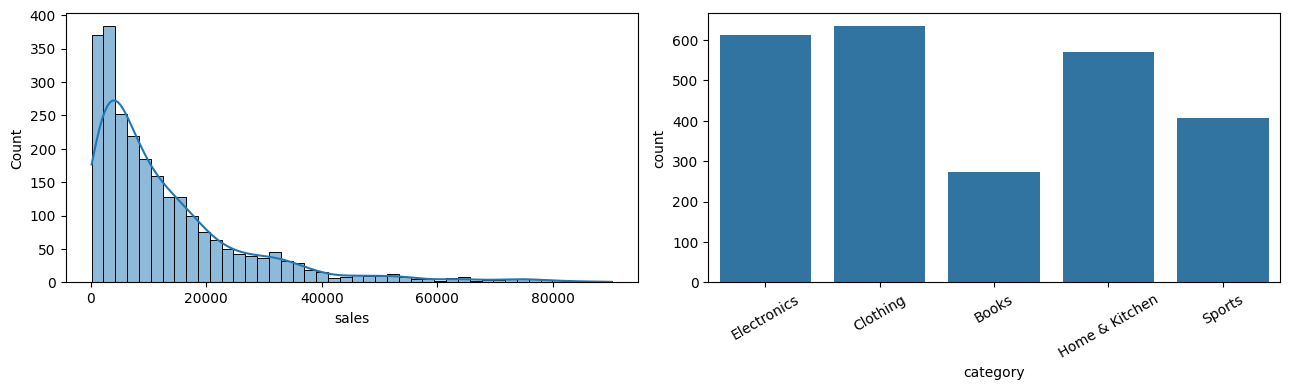

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=data, x='sales', kde=True, ax=axes[0])
sns.countplot(data=data, x='category', ax=axes[1])
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()

## 5. Bivariate and multivariate analysis

,quantity,unit_price,discount,sales,cost,profit,net_sales,profit_margin
quantity,1.00,-0.03,-0.00,0.33,0.33,0.29,0.46,0.02
unit_price,-0.03,1.00,0.02,0.80,0.79,0.69,0.77,-0.01
discount,-0.00,0.02,1.00,-0.08,0.01,-0.23,-0.07,-0.53
sales,0.33,0.80,-0.08,1.00,0.97,0.91,0.95,0.06
cost,0.33,0.79,0.01,0.97,1.00,0.79,0.93,-0.10
profit,0.29,0.69,-0.23,0.91,0.79,1.00,0.85,0.34
net_sales,0.46,0.77,-0.07,0.95,0.93,0.85,1.00,0.04
profit_margin,0.02,-0.01,-0.53,0.06,-0.10,0.34,0.04,1.00


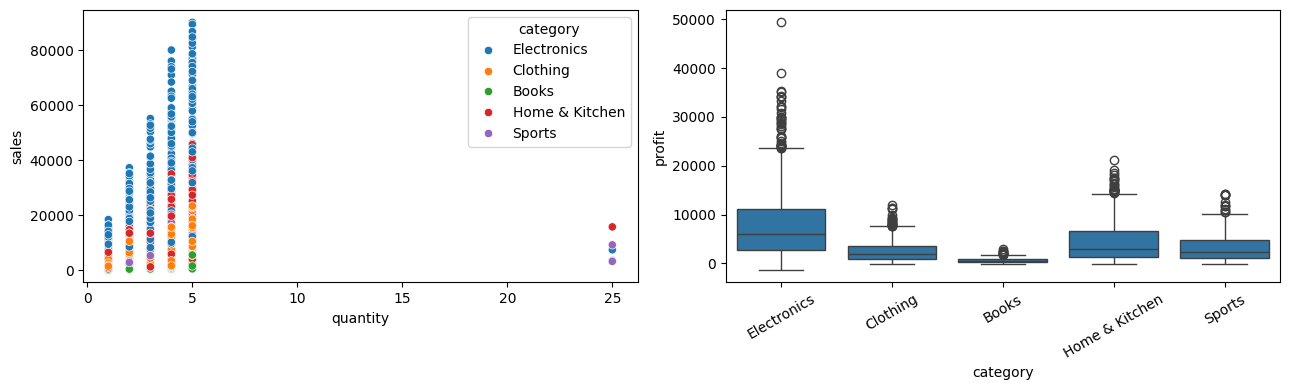

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=data, x='quantity', y='sales', hue='category', ax=axes[0])
sns.boxplot(data=data, x='category', y='profit', ax=axes[1])
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
display(data.select_dtypes('number').corr().round(2))

## 6. Time series and business summaries

,category,revenue,profit,quantity
2,Electronics,16329093.82,5189340.91,1851
3,Home & Kitchen,7636255.47,2568808.70,1744
1,Clothing,4852848.98,1613273.89,1926
4,Sports,4005734.07,1341364.46,1274
0,Books,545584.54,176123.39,868


,region,revenue,profit,orders
2,North,8386805.98,2720352.68,613
3,South,7332529.48,2418987.80,547
0,Central,6133165.59,1878773.98,455
4,West,5992703.95,1981225.27,474
1,East,5524311.88,1889571.62,411


,month,revenue,profit,orders
19,2025-08,1373615.80,422844.88,101
20,2025-09,1555004.87,506827.24,106
21,2025-10,1375489.90,540866.56,95
22,2025-11,1341817.30,496231.61,106
23,2025-12,1900742.71,714628.21,109


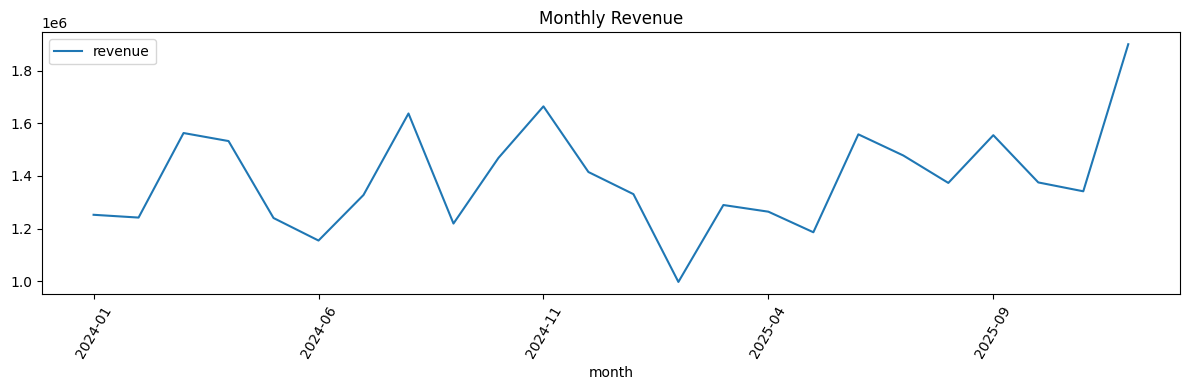

In [11]:
summary = build_analysis(data)
display(summary['category'])
display(summary['region'])
display(summary['monthly'].tail())
summary['monthly'].plot(x='month', y='revenue', figsize=(12,4), title='Monthly Revenue')
plt.xticks(rotation=60); plt.tight_layout()

## 7. Questions to investigate

- Which category contributes the most revenue and profit?
- Are the highest-revenue regions also the most profitable?
- How does order value vary by payment method?
- Are unusually large quantities valid bulk orders or data-entry errors?
- What additional data (returns, marketing spend, customer acquisition source) would improve the analysis?